In [1]:
import rasterio
from rasterio.enums import Resampling
from rasterio.warp import calculate_default_transform, reproject
from rasterio.transform import from_origin
import numpy as np
import geopandas as gpd
from shapely.geometry import Point
from shapely.geometry import box
import random
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
from scipy.stats import pearsonr
from sklearn.metrics import r2_score
import pandas as pd
import numpy as np
import rioxarray as rxr
import matplotlib as mpl
mpl.rcParams['font.family'] = 'Arial'

c:\Users\minyu\.conda\envs\ICESAT_env\lib\site-packages\cupy\_environment.py:215: UserWarning: CUDA path could not be detected. Set CUDA_PATH environment variable if CuPy fails to load.
  warnings.warn(


In [43]:
#---------------path ------------------
validation_sample_path1 = 'G:\ICESat-2\Region1_map\Thames1_map\A2019\Thames1_2019_sample_points_final.shp'
validation_sample_path2 ='G:\ICESat-2\Region2_map\Henber_map\A2019\Henber_2019_sample_points_final.shp'
validation_sample_path3 ='G:\ICESat-2\Region2_map\wash_bay_map\A2019\wash_bay_2019_sample_points_final.shp'
validation_sample_path4 ='G:\ICESat-2\Region3_map\Region3b1_map\A2019\Region3b1_2019_sample_points_final.shp'
validation_sample_path5 ='G:\ICESat-2\Region4_map\Ribble1_map\A2019\Ribble1_2019_sample_points_final.shp'
validation_sample_path6 ='G:\ICESat-2\Region4_map\Solway_map\A2019\Solway_2019_sample_points_final.shp'
validation_sample_path7 ='G:\ICESat-2\Region4_map\Morecambe_map\A2019\Morecambe_2019_sample_points_final.shp'
a = gpd.read_file(f'G:\ICESat-2\Region4_map\Parrett_map\A2020\Parrett_2020_sample_points_final.shp')
a.columns

Index(['Refer_dem', 'retrieved_', 'new7_DTM', 'new7_DTM_s', 'dif', 'geometry'], dtype='object')

In [21]:
import geopandas as gpd
import pandas as pd

year = 2022
validation_sample_paths_2022 = [
    f'H:\ICESat-2\Region1_map\Thames1_map\A{year}\Thames1_{year}_sample_points_final.shp',
    f'H:\ICESat-2\Region2_map\Henber_map\A{year}\Henber_{year}_sample_points_final.shp',
    f'H:\ICESat-2\Region2_map\wash_bay_map\A{year}\wash_bay_{year}_sample_points_final.shp',
    f'H:\ICESat-2\Region3_map\Region3b1_map\A{year}\Region3b1_2022_sample_points_final.shp',#Region3b1_2022_sample_points_final
    f'H:\ICESat-2\Region4_map\Ribble1_map\A{year}\Ribble1_{year}_sample_points_final.shp',
    f'H:\ICESat-2\Region4_map\Solway_map\A{year}\Solway_{year}_sample_points_final.shp',
    f'H:\ICESat-2\Region4_map\Morecambe_map\A{year}\Morecambe_{year}_sample_points_final.shp',
    f'H:\ICESat-2\Region4_map\Baglan_map\A2022\Baglan_2022_sample_points_final.shp',# SWansea Bay
    f'H:\ICESat-2\Region4_map\AfonDyfi_map\A2022\AfonDyfi_2022_sample_points_final.shp',
    f'H:\ICESat-2\Region4_map\Ribble_map\A{year}\Ribble_{year}_sample_points.shp', #Dee
    f"H:\ICESat-2\Region3_map\Region3c_map\A{year}\Region3c_{year}_sample_points.shp",
    f"H:\ICESat-2\Region5_map\Carmarthen_map\A2022\Carmarthen_2022_sample_points_final.shp",
    
]


target_crs = "EPSG:32630"   # WGS84 / UTM zone 30N

gdf_list = []

for path in validation_sample_paths_2022:

    gdf = gpd.read_file(path)

    # 转换到统一投影
    gdf = gdf.to_crs(target_crs)

    gdf_list.append(gdf)

# =========================
# 合并
# =========================
merged_gdf = gpd.GeoDataFrame(
    pd.concat(gdf_list, ignore_index=True),
    crs=target_crs
)

# =========================

output_path = fr'H:\ICESat-2\Validation_all_lidar\merged_validation_samples_{year}.shp'

merged_gdf.to_file(output_path)

print('Merged shapefile saved to:')
print(output_path)

Merged shapefile saved to:
H:\ICESat-2\Validation_all_lidar\merged_validation_samples_2022.shp


In [2]:
# 所有路径放入列表中
year = 2019
validation_sample_paths_2019 = [
    f'H:\ICESat-2\Region1_map\Thames1_map\A{year}\Thames1_{year}_sample_points_final.shp',
    f'H:\ICESat-2\Region2_map\Henber_map\A{year}\Henber_{year}_sample_points_final.shp',
    f'H:\ICESat-2\Region2_map\wash_bay_map\A{year}\wash_bay_{year}_sample_points_final.shp',
    f'H:\ICESat-2\Region3_map\Region3b1_map\A{year}\Region3b1_{year}_sample_points_final.shp',
    f'H:\ICESat-2\Region4_map\Ribble1_map\A{year}\Ribble1_{year}_sample_points_final.shp',
    f'H:\ICESat-2\Region4_map\Solway_map\A{year}\Solway_{year}_sample_points_final.shp',
    f'H:\ICESat-2\Region4_map\Morecambe_map\A{year}\Morecambe_{year}_sample_points_final.shp',
    f'H:\ICESat-2\Region4_map\Ribble_map\A{year}\Ribble_{year}_sample_points.shp'
]

year = 2020
validation_sample_paths_2020 = [
    f'H:\ICESat-2\Region1_map\Thames1_map\A{year}\Thames1_{year}_sample_points_final.shp',
    f'H:\ICESat-2\Region2_map\Henber_map\A{year}\Henber_{year}_sample_points_final.shp',
    f'H:\ICESat-2\Region2_map\wash_bay_map\A{year}\wash_bay_{year}_sample_points_final.shp',
    f'H:\ICESat-2\Region4_map\Ribble1_map\A{year}\Ribble1_{year}_sample_points_final.shp',
    f'H:\ICESat-2\Region4_map\Solway_map\A{year}\Solway_{year}_sample_points_final.shp',
    f'H:\ICESat-2\Region4_map\Morecambe_map\A{year}\Morecambe_{year}_sample_points_final.shp',
    f'H:\ICESat-2\Region4_map\Parrett_map\A2020\Parrett_2020_sample_points_final.shp',
    f"H:\ICESat-2\Region3_map\Region3c_map\A2020\Region3c_2020_sample_points_final.shp",
    f'H:\ICESat-2\Region4_map\Ribble_map\A{year}\Ribble_{year}_sample_points.shp'
]

year = 2021
validation_sample_paths_2021 = [
    f'H:\ICESat-2\Region1_map\Thames1_map\A{year}\Thames1_{year}_sample_points_final.shp',
    f'H:\ICESat-2\Region2_map\Henber_map\A{year}\Henber_{year}_sample_points_final.shp',
    f'H:\ICESat-2\Region2_map\wash_bay_map\A{year}\wash_bay_{year}_sample_points_final.shp',
    f'H:\ICESat-2\Region3_map\Region3b1_map\A{year}\Region3b1_{year}_sample_points_final.shp',
    f'H:\ICESat-2\Region4_map\Ribble1_map\A{year}\Ribble1_{year}_sample_points_final.shp',
    f'H:\ICESat-2\Region4_map\Solway_map\A{year}\Solway_{year}_sample_points_final.shp',
    f'H:\ICESat-2\Region4_map\Morecambe_map\A{year}\Morecambe_{year}_sample_points_final.shp',
    f'H:\ICESat-2\Region4_map\Araw_map\A2021\Araw_2021_sample_points_final.shp',
    f'H:\ICESat-2\Region4_map\Ribble_map\A{year}\Ribble_{year}_sample_points.shp',
    f"H:\ICESat-2\Region3_map\Region3c_map\A{year}\Region3c_{year}_sample_points_final.shp",
]

year = 2022
validation_sample_paths_2022 = [
    f'H:\ICESat-2\Region1_map\Thames1_map\A{year}\Thames1_{year}_sample_points_final.shp',
    f'H:\ICESat-2\Region2_map\Henber_map\A{year}\Henber_{year}_sample_points_final.shp',
    f'H:\ICESat-2\Region2_map\wash_bay_map\A{year}\wash_bay_{year}_sample_points_final.shp',
    f'H:\ICESat-2\Region3_map\Region3b1_map\A{year}\Region3b1_2022_sample_points_final.shp',#Region3b1_2022_sample_points_final
    f'H:\ICESat-2\Region4_map\Ribble1_map\A{year}\Ribble1_{year}_sample_points_final.shp',
    f'H:\ICESat-2\Region4_map\Solway_map\A{year}\Solway_{year}_sample_points_final.shp',
    f'H:\ICESat-2\Region4_map\Morecambe_map\A{year}\Morecambe_{year}_sample_points_final.shp',
    f'H:\ICESat-2\Region4_map\Baglan_map\A2022\Baglan_2022_sample_points_final.shp',# SWansea Bay
    f'H:\ICESat-2\Region4_map\AfonDyfi_map\A2022\AfonDyfi_2022_sample_points_final.shp',
    f'H:\ICESat-2\Region4_map\Ribble_map\A{year}\Ribble_{year}_sample_points.shp', #Dee
    f"H:\ICESat-2\Region3_map\Region3c_map\A{year}\Region3c_{year}_sample_points.shp",
    f"H:\ICESat-2\Region5_map\Carmarthen_map\A2022\Carmarthen_2022_sample_points_final.shp",
    
]

year = 2023
validation_sample_paths_2023 = [
    f'H:\ICESat-2\Region1_map\Thames1_map\A{year}\Thames1_{year}_sample_points_final.shp',
    f'H:\ICESat-2\Region2_map\Henber_map\A{year}\Henber_{year}_sample_points_final.shp',
    f'H:\ICESat-2\Region2_map\wash_bay_map\A{year}\wash_bay_{year}_sample_points_final.shp',
    f'H:\ICESat-2\Region3_map\Region3b1_map\A{year}\Region3b1_{year}_sample_points_final.shp',
    f'H:\ICESat-2\Region4_map\Ribble1_map\A{year}\Ribble1_{year}_sample_points_final.shp',
    f'H:\ICESat-2\Region4_map\Solway_map\A{year}\Solway_{year}_sample_points_final.shp',
    f'H:\ICESat-2\Region4_map\Morecambe_map\A{year}\Morecambe_{year}_sample_points_final.shp',
    f'H:\ICESat-2\Region4_map\Parrett_map\A2023\Parrett_2023_sample_points_final.shp',
    f'H:\ICESat-2\Region4_map\Ribble_map\A{year}\Ribble_{year}_sample_points.shp', #Dee
]

year = 2024
validation_sample_paths_2024 = [

    f'H:\ICESat-2\Region2_map\wash_bay_map\A{year}\wash_bay_{year}_sample_points_final.shp',
    f'H:\ICESat-2\Region1_map\Thames1_map\A{year}\Thames1_{year}_sample_points_final.shp',
    f'H:\ICESat-2\Region2_map\Henber_map\A{year}\Henber_{year}_sample_points_final.shp',
    
]


# 读取并提取指定列
# gdf_list = []
# for path in validation_sample_paths_2019:
#     gdf = gpd.read_file(path)
#     gdf_selected = gdf[['Refer_dem', 'DEM_new9']]  # 只保留所需字段
#     gdf_list.append(gdf_selected)

# # 合并所有 GeoDataFrame
# merged_gdf = pd.concat(gdf_list, ignore_index=True)

gdf_list = []
validation_sample_paths_all = [validation_sample_paths_2019, validation_sample_paths_2020,
                               validation_sample_paths_2021, validation_sample_paths_2022,
                               validation_sample_paths_2023, validation_sample_paths_2024]

for validation_sample_paths  in validation_sample_paths_all:
    for path in validation_sample_paths:
    
        gdf = gpd.read_file(path)
        gdf_selected = gdf[['Refer_dem', 'DEM_new9']]  # 只保留所需字段
        gdf_list.append(gdf_selected)
# 合并所有 GeoDataFrame
merged_gdf = pd.concat(gdf_list, ignore_index=True)




In [3]:
len(merged_gdf)
z = merged_gdf.dropna()
mask = z['DEM_new9'] != 0
z = z[mask]
z = z[z['Refer_dem']!=0]
z = z[z['Refer_dem']!=6]
x = np.array(z['Refer_dem']) #y_true
y = np.array(z['DEM_new9']) # y_pred

    # R, _ = pearsonr(y, x)
R2 = r2_score(x, y) #r2_score(y_true, y_pred)
MAE = np.mean(np.abs(y-x))
MSB = np.mean((y-x))
RMSE = np.sqrt(np.mean((y-x)**2))
num = int(len(x))
print(num)
print(f"R² = {R2:.3f}, MAE = {MAE:.3f}, RMSE = {RMSE:.3f}, N = {num}")

101646
R² = 0.844, MAE = 0.445, RMSE = 0.660, N = 101646


In [2]:
wash_validation = [f'G:\ICESat-2\Region2_map\wash_bay_map\A2019\wash_bay_2019_sample_points_final.shp',
                   f'G:\ICESat-2\Region2_map\wash_bay_map\A2020\wash_bay_2020_sample_points_final.shp',
                   f'G:\ICESat-2\Region2_map\wash_bay_map\A2021\wash_bay_2021_sample_points_final.shp',
                   f'G:\ICESat-2\Region2_map\wash_bay_map\A2022\wash_bay_2022_sample_points_final.shp',
                   f'G:\ICESat-2\Region2_map\wash_bay_map\A2023\wash_bay_2023_sample_points_final.shp',
                   f'G:\ICESat-2\Region2_map\wash_bay_map\A2024\wash_bay_2024_sample_points_final.shp']

Humber_validation = [f'G:\ICESat-2\Region2_map\Henber_map\A2019\Henber_2019_sample_points_final.shp',
                   f'G:\ICESat-2\Region2_map\Henber_map\A2020\Henber_2020_sample_points_final.shp',
                   f'G:\ICESat-2\Region2_map\Henber_map\A2021\Henber_2021_sample_points_final.shp',
                   f'G:\ICESat-2\Region2_map\Henber_map\A2022\Henber_2022_sample_points_final.shp',
                   f'G:\ICESat-2\Region2_map\Henber_map\A2023\Henber_2023_sample_points_final.shp',
                   f'G:\ICESat-2\Region2_map\Henber_map\A2024\Henber_2024_sample_points_final.shp']

Thames_validation = [f'G:\ICESat-2\Region1_map\Thames1_map\A2019\Thames1_2019_sample_points_final.shp',
                     f'G:\ICESat-2\Region1_map\Thames1_map\A2020\Thames1_2020_sample_points_final.shp',
                     f'G:\ICESat-2\Region1_map\Thames1_map\A2021\Thames1_2021_sample_points_final.shp',
                     f'G:\ICESat-2\Region1_map\Thames1_map\A2022\Thames1_2022_sample_points_final.shp',
                     f'G:\ICESat-2\Region1_map\Thames1_map\A2023\Thames1_2023_sample_points_final.shp',
                     f'G:\ICESat-2\Region1_map\Thames1_map\A2024\Thames1_2024_sample_points_final.shp',]

Holy_validation = [f'G:\ICESat-2\Region3_map\Region3b1_map\A2019\Region3b1_2019_sample_points_final.shp',
                   f'G:\ICESat-2\Region3_map\Region3b1_map\A2021\Region3b1_2021_sample_points_final.shp',
                   f'G:\ICESat-2\Region3_map\Region3b1_map\A2022\Region3b1_2022_sample_points_final.shp',
                   f'G:\ICESat-2\Region3_map\Region3b1_map\A2023\Region3b1_2023_sample_points_final.shp',]

Ribble_validation = [f'G:\ICESat-2\Region4_map\Ribble1_map\A2019\Ribble1_2019_sample_points_final.shp',
                     f'G:\ICESat-2\Region4_map\Ribble1_map\A2020\Ribble1_2020_sample_points_final.shp',
                     f'G:\ICESat-2\Region4_map\Ribble1_map\A2021\Ribble1_2021_sample_points_final.shp',
                     f'G:\ICESat-2\Region4_map\Ribble1_map\A2022\Ribble1_2022_sample_points_final.shp',
                     f'G:\ICESat-2\Region4_map\Ribble1_map\A2023\Ribble1_2023_sample_points_final.shp',]

Solway_validation = [f'G:\ICESat-2\Region4_map\Solway_map\A2019\Solway_2019_sample_points_final.shp',
                     f'G:\ICESat-2\Region4_map\Solway_map\A2020\Solway_2020_sample_points_final.shp',
                     f'G:\ICESat-2\Region4_map\Solway_map\A2021\Solway_2021_sample_points_final.shp',
                     f'G:\ICESat-2\Region4_map\Solway_map\A2022\Solway_2022_sample_points_final.shp',
                     f'G:\ICESat-2\Region4_map\Solway_map\A2023\Solway_2023_sample_points_final.shp',]

Morecambe_validation = [f'G:\ICESat-2\Region4_map\Morecambe_map\A2019\Morecambe_2019_sample_points_final.shp',
                        f'G:\ICESat-2\Region4_map\Morecambe_map\A2020\Morecambe_2020_sample_points_final.shp',
                        f'G:\ICESat-2\Region4_map\Morecambe_map\A2021\Morecambe_2021_sample_points_final.shp',
                        f'G:\ICESat-2\Region4_map\Morecambe_map\A2022\Morecambe_2022_sample_points_final.shp',
                        f'G:\ICESat-2\Region4_map\Morecambe_map\A2023\Morecambe_2023_sample_points_final.shp',]

Dee_validation = [f'G:\ICESat-2\Region4_map\Ribble_map\A2019\Ribble_2019_sample_points.shp', 
                  f'G:\ICESat-2\Region4_map\Ribble_map\A2020\Ribble_2020_sample_points.shp', 
                  f'G:\ICESat-2\Region4_map\Ribble_map\A2021\Ribble_2021_sample_points.shp', 
                  f'G:\ICESat-2\Region4_map\Ribble_map\A2022\Ribble_2022_sample_points.shp', 
                  f'G:\ICESat-2\Region4_map\Ribble_map\A2023\Ribble_2023_sample_points.shp',]

Hayling_validation = [f"G:\ICESat-2\Region3_map\Region3c_map\A2020\Region3c_2020_sample_points_final.shp",
                      f"G:\ICESat-2\Region3_map\Region3c_map\A2021\Region3c_2021_sample_points_final.shp",
                      f"G:\ICESat-2\Region3_map\Region3c_map\A2022\Region3c_2022_sample_points.shp",]

Bridgwater_validation = [f'G:\ICESat-2\Region4_map\Parrett_map\A2020\Parrett_2020_sample_points_final.shp',
                         
                         f'G:\ICESat-2\Region4_map\Parrett_map\A2023\Parrett_2023_sample_points_final.shp',]

In [3]:
k = gpd.read_file(f'G:\ICESat-2\Region4_map\Ribble_map\A2019\Ribble_2019_sample_points.shp')
k.columns

Index(['Refer_dem', 'retrieved_', 'DEM_new9', 'L89_NEF', 'NEF', 'S2_NEF',
       'DEM_join', 'geometry'],
      dtype='object')

In [4]:
estuaries_list = [wash_validation, Humber_validation, Thames_validation, Holy_validation, Ribble_validation,
                  Solway_validation, Morecambe_validation, Dee_validation, Hayling_validation, Bridgwater_validation]
estuaries_list = [Dee_validation]
a = 0
for estuary_path in estuaries_list:
    
    merged_gdf = []
    gdf_list = []
    
    for path in estuary_path:
        
        gdf = gpd.read_file(path)
        gdf_selected = gdf[['Refer_dem', 'DEM_join']]
        gdf_list.append(gdf_selected)
    merged_gdf = pd.concat(gdf_list, ignore_index= True)
    
    z = merged_gdf.dropna()
    mask = z['DEM_join'] != 0
    z = z[mask]
    z = z[z['Refer_dem']!=0]
    z = z[z['Refer_dem']!=6]
    x = np.array(z['Refer_dem']) #y_true
    y = np.array(z['DEM_join']) # y_pred
    R2 = r2_score(x, y) #r2_score(y_true, y_pred)
    MAE = np.mean(np.abs(y-x))
    MSB = np.mean((y-x))
    RMSE = np.sqrt(np.mean((y-x)**2))
    num = int(len(x))

    a += num
    print(f"{estuary_path[0]},'\n' R² = {R2:.3f}, MAE = {MAE:.3f}, RMSE = {RMSE:.3f}, N = {num}")

G:\ICESat-2\Region4_map\Ribble_map\A2019\Ribble_2019_sample_points.shp,'
' R² = 0.572, MAE = 0.887, RMSE = 1.174, N = 8678


In [ ]:
# wash 
merged_gdf = []
gdf_list = []
wash_validation = [f'G:\ICESat-2\Region2_map\wash_bay_map\A2019\wash_bay_2019_sample_points_final.shp',
                   f'G:\ICESat-2\Region2_map\wash_bay_map\A2020\wash_bay_2020_sample_points_final.shp',
                   f'G:\ICESat-2\Region2_map\wash_bay_map\A2021\wash_bay_2021_sample_points_final.shp',
                   f'G:\ICESat-2\Region2_map\wash_bay_map\A2022\wash_bay_2022_sample_points_final.shp',
                   f'G:\ICESat-2\Region2_map\wash_bay_map\A2023\wash_bay_2023_sample_points_final.shp',
                   f'G:\ICESat-2\Region2_map\wash_bay_map\A2024\wash_bay_2024_sample_points_final.shp']


for path in wash_validation:
    
    gdf = gpd.read_file(path)
    gdf_selected = gdf[['Refer_dem', 'DEM_new9']]
    gdf_list.append(gdf_selected)
merged_gdf = pd.concat(gdf_list, ignore_index=True)

z = merged_gdf.dropna()
mask = z['DEM_new9'] != 0
z = z[mask]
z = z[z['Refer_dem']!=0]
z = z[z['Refer_dem']!=6]
x = np.array(z['Refer_dem']) #y_true
y = np.array(z['DEM_new9']) # y_pred
xy_lim_range = [-6, 5]
    # R, _ = pearsonr(y, x)
R2 = r2_score(x, y) #r2_score(y_true, y_pred)
MAE = np.mean(np.abs(y-x))
MSB = np.mean((y-x))
RMSE = np.sqrt(np.mean((y-x)**2))
num = int(len(x))

print(f"R² = {R2:.3f}, MAE = {MAE:.3f}, RMSE = {RMSE:.3f}, N = {num}")

R² = 0.933, MAE = 0.256, RMSE = 0.346, N = 22216


In [ ]:
year = 2024
validation_sample_paths_2024 = [

    f'G:\ICESat-2\Region2_map\wash_bay_map\A{year}\wash_bay_{year}_sample_points_final.shp',
    f'G:\ICESat-2\Region1_map\Thames1_map\A{year}\Thames1_{year}_sample_points_final.shp',
    f'G:\ICESat-2\Region2_map\Henber_map\A{year}\Henber_{year}_sample_points_final.shp',
    
]

for path in validation_sample_paths_2024:
    
    gdf = gpd.read_file(path)
    gdf_selected = gdf[['Refer_dem', 'DEM_new9']]
    gdf_list
    


In [26]:
merged_gdf = []
gdf_list = []
for path in validation_sample_paths_2020:
    
    gdf = gpd.read_file(path)
    gdf_selected = gdf[['Refer_dem', 'DEM_new9']]  # 只保留所需字段
    gdf_list.append(gdf_selected)
merged_gdf = pd.concat(gdf_list, ignore_index=True)


In [ ]:
# k2 = merged_gdf[(merged_gdf['Refer_dem'] < -4) &(merged_gdf['Refer_dem'] >-5)]
# len(k2)

value_list = [-4, -3, -2, -1, 0, 1, 2, 3, 4, 5]

# value_list = [-4, -3.5, -3, -2.5, -2, -1.5, -1, -0.5, 0, 0.5, 1, 1.5, 2, 2.5, 3, 3.5, 4, 4.5, 5]

z = merged_gdf.dropna()
mask = z['DEM_new9'] != 0
z = z[mask]
z = z[z['Refer_dem']!=0]
z = z[z['Refer_dem']!=6]
print(len(z))
print('Retrival DEM:')
for v in value_list:

    
    k = z[(z['Refer_dem'] < v+1) &(z['Refer_dem'] > v)]
    x = np.array(k['Refer_dem']) #y_true
    y = np.array(k['DEM_new9']) #
    RMSE = np.sqrt(np.mean((y-x)**2))
    num = len(k)
    print(f'num: {num}',f'range: [{v}, {v+1}], RMSE:', f"RMSE.3f")

In [14]:
a = gpd.read_file(f'H:\ICESat-2\Region2_map\wash_bay_map\A2021\wash_bay_2021_sample_points_final.shp')
a.columns

Index(['Refer_dem', 'retrieved_', 'AAA', 'SY', 'DEM_new9', 'Refer_dem_',
       'DEM_new9_3', 'DEM9_SY', 'DEM_new9_', 'Wash_p5', 'geometry'],
      dtype='object')

R² = 0.905, MAE = 0.284, RMSE = 0.396, N = 3324


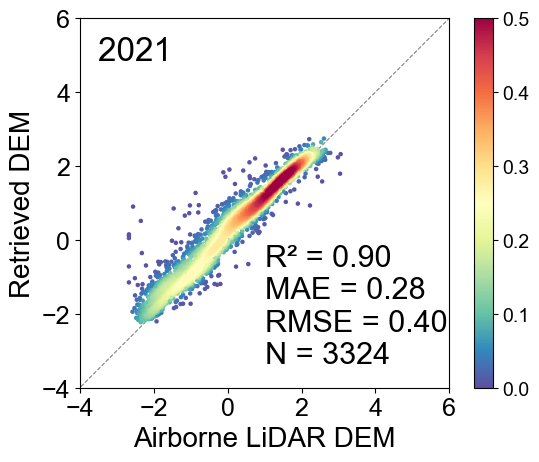

In [16]:
merged_gdf = []
gdf_list = []
year = 2021

validation_sample_paths_2019 = [f'H:\ICESat-2\Region2_map\wash_bay_map\A2021\wash_bay_2021_sample_points_final.shp',]
for path in validation_sample_paths_2019:
    
    gdf = gpd.read_file(path)
    #gdf_selected = gdf[['Refer_dem', 'DEM_new9']]  # 只保留所需字段
    gdf_selected = gdf[['Refer_dem', 'DEM_new9']] 
    gdf_list.append(gdf_selected)
merged_gdf = pd.concat(gdf_list, ignore_index=True)


z = merged_gdf.dropna()
mask = z['DEM_new9'] != 0
z = z[mask]
z = z[z['Refer_dem']!=0]
z = z[z['Refer_dem']!=6]
x = np.array(z['Refer_dem']) #y_true
y = np.array(z['DEM_new9']) # y_pred
xy_lim_range = [-6, 5]
    # R, _ = pearsonr(y, x)
R2 = r2_score(x, y) #r2_score(y_true, y_pred)
MAE = np.mean(np.abs(y-x))
MSB = np.mean((y-x))
RMSE = np.sqrt(np.mean((y-x)**2))
num = int(len(x))

print(f"R² = {R2:.3f}, MAE = {MAE:.3f}, RMSE = {RMSE:.3f}, N = {num}")
    
xy = np.vstack([x,y])  #  将两个维度的数据叠加
z = gaussian_kde(xy)(xy)  # 建立概率密度分布，并计算每个样本点的概率密度

    # Sort the points by density, so that the densest points are plotted last
idx = z.argsort()
x_sorted, y_sorted, z_sorted = x[idx], y[idx], z[idx]

fig, ax = plt.subplots()
textstr = f"R² = {R2:.2f}\nMAE = {MAE:.2f}\nRMSE = {RMSE:.2f} \nN = {num}"
name = year#f'{location2} ({year})'
#ax.text(0.05, 0.95, textstr, transform = ax.transAxes, fontsize = 16, verticalalignment = 'top')
# ax.text(0.95, 0.05, name, transform=ax.transAxes, fontsize=16, verticalalignment='bottom', horizontalalignment='right')

ax.text(
        0.5, 0.05,
        textstr,
        transform=ax.transAxes,
        fontsize=22,
        verticalalignment='bottom',
        linespacing=1.2   # 默认是 1.0，调大就会加宽行间距
)
ax.text(0.05, 0.95, name, transform=ax.transAxes, fontsize=24,
        verticalalignment='top',)

ax.set_xlabel('Airborne LiDAR DEM', fontsize = 20)
ax.set_ylabel('Retrieved DEM', fontsize = 20)
ax.plot([-6, 6], [-6, 6], color='gray', linestyle='--', linewidth=0.8, zorder=1)

sc = plt.scatter(x_sorted, y_sorted, c=z_sorted,  vmin=0, vmax=0.5, s=5, cmap='Spectral_r', zorder=2)
cbar = plt.colorbar(sc)
cbar.ax.tick_params(labelsize=14)
    # plt.scatter(x, y,c=z, s=2,cmap='Spectral_r') # c表示标记的颜色
    # plt.colorbar()

ax.set_xlim(-4, 5)
ax.set_ylim(-4, 5)

# 设置一致的刻度间隔（例如每 1 单位一个刻度）
tick_interval = 2
ticks = np.arange(-4, 5 + tick_interval, tick_interval)
ax.set_xticks(ticks)
ax.set_yticks(ticks)
ax.tick_params(axis='both', labelsize=18)
# 设置等比例显示
ax.set_aspect('equal')

        
# plt.savefig(output_path, dpi=300, bbox_inches='tight')  # 保存图像
plt.show()
plt.close()